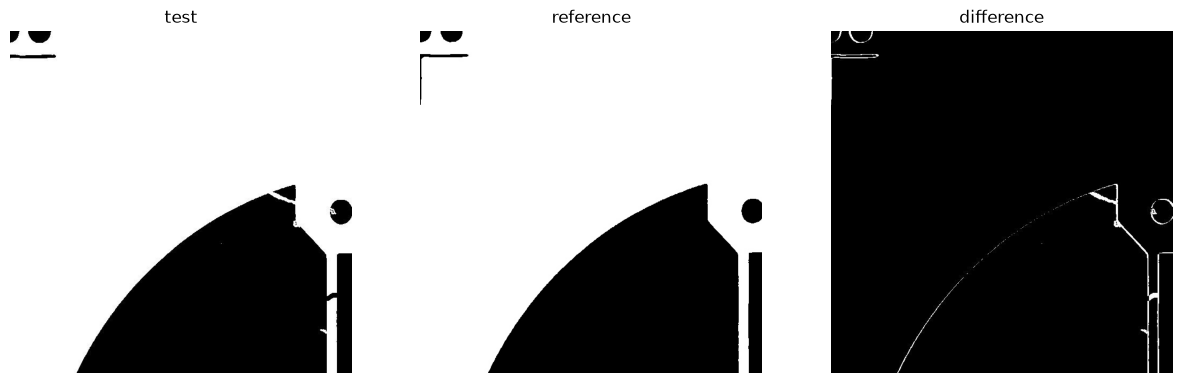

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent
RAW = ROOT / "data/raw/DeepPCB/PCBData"
val_csv = ROOT / "data/processed/splits/val.csv"

df = pd.read_csv(val_csv)
row = df.iloc[0]

test = cv2.imread(str(RAW / row["test_img"]), cv2.IMREAD_GRAYSCALE)
ref = cv2.imread(str(RAW / row["ref_img"]), cv2.IMREAD_GRAYSCALE)
diff = cv2.absdiff(test, ref)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(axes, [test, ref, diff], ["test", "reference", "difference"]):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()

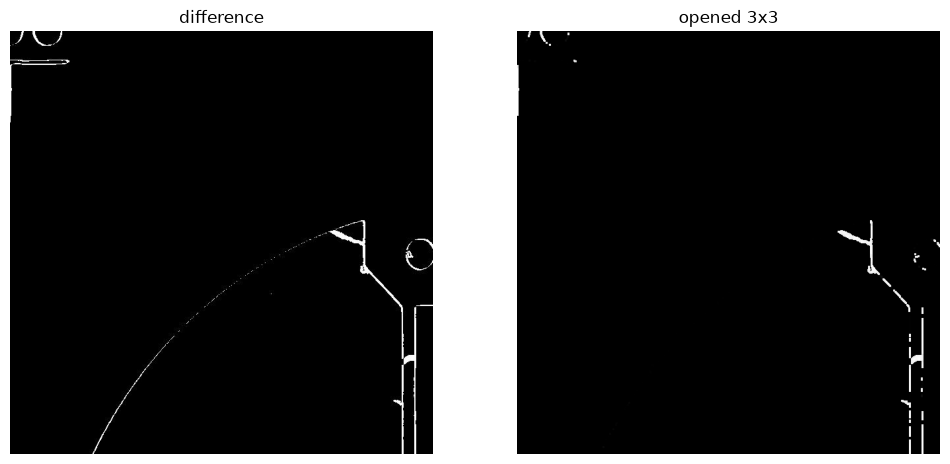

In [2]:
import numpy as np

kernel = np.ones((3, 3), np.uint8)
opened = cv2.morphologyEx(diff, cv2.MORPH_OPEN, kernel)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, img, title in zip(axes, [diff, opened], ["difference", "opened 3x3"]):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()

ground truth: 5 predicted: 65


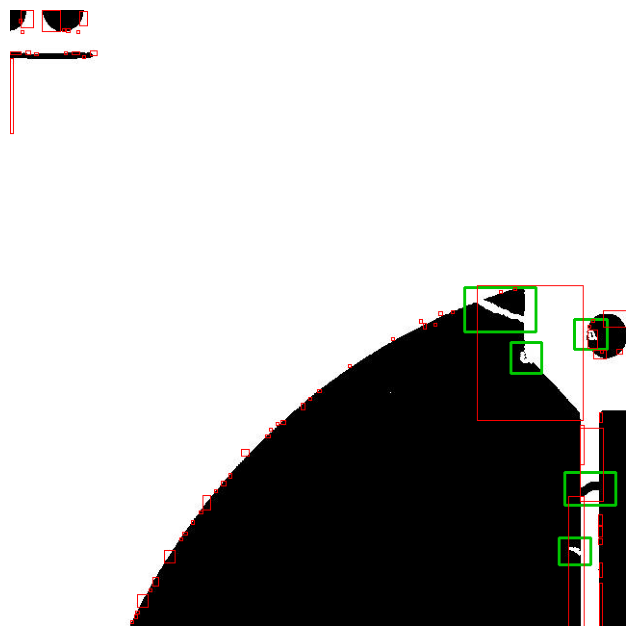

In [3]:
n, labels, stats, _ = cv2.connectedComponentsWithStats(opened, connectivity=8)

pred_boxes = []
for i in range(1, n):
    x, y, w, h, area = stats[i]
    pred_boxes.append((x, y, x + w, y + h))

gt = np.loadtxt(RAW / row["ann"], dtype=int, ndmin=2)
gt_boxes = gt[:, :4]

canvas = cv2.cvtColor(test, cv2.COLOR_GRAY2RGB)
for x1, y1, x2, y2 in gt_boxes:
    cv2.rectangle(canvas, (x1, y1), (x2, y2), (0, 200, 0), 2)
for x1, y1, x2, y2 in pred_boxes:
    cv2.rectangle(canvas, (x1, y1), (x2, y2), (255, 0, 0), 1)

print("ground truth:", len(gt_boxes), "predicted:", len(pred_boxes))
plt.figure(figsize=(8, 8))
plt.imshow(canvas)
plt.axis("off")
plt.show()

In [4]:
def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    return inter / (area_a + area_b - inter)

scores = stats[1:, 4]
order = np.argsort(-scores)

matched_gt = set()
tp = 0
for i in order:
    ious = [0 if j in matched_gt else iou(pred_boxes[i], g) for j, g in enumerate(gt_boxes)]
    best = int(np.argmax(ious))
    if ious[best] >= 0.5:
        tp += 1
        matched_gt.add(best)

fp = len(pred_boxes) - tp
fn = len(gt_boxes) - tp
print("TP:", tp, "FP:", fp, "FN:", fn)

TP: 0 FP: 65 FN: 5


In [5]:
for j, g in enumerate(gt_boxes):
    ious = [iou(p, g) for p in pred_boxes]
    best = int(np.argmax(ious))
    p = pred_boxes[best]
    print(
        f"gt {j}: best iou {ious[best]:.2f} | "
        f"gt size {g[2] - g[0]}x{g[3] - g[1]} | "
        f"pred size {p[2] - p[0]}x{p[3] - p[1]}"
    )

gt 0: best iou 0.18 | gt size 74x46 | pred size 110x140
gt 1: best iou 0.25 | gt size 53x34 | pred size 24x76
gt 2: best iou 0.18 | gt size 34x31 | pred size 10x19
gt 3: best iou 0.07 | gt size 32x32 | pred size 110x140
gt 4: best iou 0.17 | gt size 33x28 | pred size 16x135


In [8]:
from collections import Counter

def best_shift(test, ref, max_shift=3):
    m = max_shift
    h, w = test.shape
    t = test[m:h - m, m:w - m]
    best, best_count = None, None
    for dy in range(-m, m + 1):
        for dx in range(-m, m + 1):
            r = ref[m + dy:h - m + dy, m + dx:w - m + dx]
            count = np.count_nonzero(cv2.absdiff(t, r) > 127)
            if best_count is None or count < best_count:
                best, best_count = (dx, dy), count
    return best

train_df = pd.read_csv(ROOT / "data/processed/splits/train.csv")
shifts = []
for _, r in train_df.iterrows():
    t = cv2.imread(str(RAW / r["test_img"]), cv2.IMREAD_GRAYSCALE)
    f = cv2.imread(str(RAW / r["ref_img"]), cv2.IMREAD_GRAYSCALE)
    shifts.append(best_shift(t, f, max_shift=8))

counts = Counter(shifts)
for s, c in counts.most_common():
    print(s, c)

(0, 0) 633
(1, 0) 31
(0, 1) 23
(-1, 0) 18
(0, -1) 17
(1, 1) 9
(0, 2) 8
(2, 0) 7
(1, -1) 5
(1, 3) 4
(0, 5) 3
(-1, 1) 3
(-8, -8) 3
(0, 4) 2
(-1, -1) 2
(-1, 6) 2
(1, 2) 2
(1, 5) 2
(-1, 4) 2
(5, 0) 2
(-4, 5) 1
(-1, 7) 1
(3, 7) 1
(0, 6) 1
(-1, 5) 1
(2, 4) 1
(0, 3) 1
(-1, 3) 1
(3, 0) 1
(4, 0) 1
(6, 0) 1
(7, 0) 1
(8, 7) 1
(8, 8) 1
(8, 1) 1
(-3, 3) 1
(0, -2) 1
(0, -8) 1
(0, 8) 1
(0, -5) 1
(0, -3) 1
(-1, 2) 1


In [9]:
mag = Counter(max(abs(dx), abs(dy)) for dx, dy in shifts)
for k in sorted(mag):
    print(k, mag[k], f"{mag[k] / len(shifts):.1%}")

0 633 79.1%
1 108 13.5%
2 19 2.4%
3 9 1.1%
4 6 0.8%
5 10 1.2%
6 4 0.5%
7 3 0.4%
8 8 1.0%
